# S1 · Government collapse: what the 8 clean episodes show

When a government falls, what happens to trust in parliament? This notebook looks at the **8 past episodes where the result can be read most safely** and puts France next to them.

**What this is:** a side-by-side description of 8 cases. It fits no model, estimates no effect, and makes no forecast.

**What "clean" means:** no parliamentary election and no other reviewed government crisis happened between the event and the survey that measures "after". Other shocks can still overlap, and the flags below say which ones.

France (Barnier, December 2024) is **held out**: it is the case we want to apply the results to, so it is shown for comparison but never used to build the picture. The reasoning behind each case is in [`docs/s1_review_cases.md`](../docs/s1_review_cases.md); every column is defined in [`s1_variable_dictionary.csv`](../data/processed/s1_variable_dictionary.csv).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from trust_windows import ISO3_TO_EB, load_waves

pd.set_option('display.float_format', '{:.1f}'.format)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 60)
BLUE, RED, GREY, LIGHT = '#245f91', '#c45d3f', '#8a98a6', '#d9e2ea'

COUNTRY = {'BGR': 'Bulgaria', 'CZE': 'Czechia', 'EST': 'Estonia', 'FRA': 'France', 'MLT': 'Malta',
           'NLD': 'Netherlands', 'ROU': 'Romania', 'SVK': 'Slovakia', 'SWE': 'Sweden'}
HOW = {'successful_no_confidence_vote': 'lost a no-confidence vote', 'budget_vote_defeat': 'lost a budget vote',
       'resignation_after_budget_talks_failed': 'resigned after budget talks failed',
       'resignation_after_party_withdrawal': 'resigned after a party withdrew'}
GOV = {'MWC': 'minimal-winning coalition', 'MPMi': 'multi-party minority', 'SPMi': 'single-party minority',
       'SPMa': 'single-party majority', 'OC': 'oversized coalition'}

d = pd.read_csv(ROOT / 'data/processed/s1_episode_dataset.csv')
d['flags'] = d['flags'].fillna('')
d['episode'] = [f"{COUNTRY[r.iso3]} {r.episode_id.split('_')[1]}" for r in d.itertuples()]
d['short'] = [f"{r.iso3} {r.episode_id.split('_')[1][2:]}" for r in d.itertuples()]
d['event_date'] = pd.to_datetime(d.event_date)

CHANGE = 'parl_change_beyond_comparison_pp'
clean = d[d.sample_group == 'clean'].sort_values('event_date').reset_index(drop=True)
broad = d[d.sample_group == 'broad_only']
france = d[d.sample_group == 'held_out'].iloc[0]
print(f"{len(d)} reviewed S1 episodes, in these groups:")
d.sample_group.value_counts().rename('episodes').to_frame()

14 reviewed S1 episodes, in these groups:


,episodes
sample_group,
clean,8
broad_only,3
no_post_wave,2
held_out,1


## 1. Which episodes are in

| Group | Meaning |
| --- | --- |
| **clean** | The 8 episodes this notebook describes. |
| **broad_only** | A complete trust window, but an election falls before the "after" survey (Bulgaria 2022, Malta 2012, Netherlands 2012). Shown in grey for context only. |
| **no_post_wave** | No survey starts 3 to 9 months after the event yet (Romania 2018 and 2019). |
| **held_out** | France 2024. Compared with the 8, never part of them. |

**Four of the eight are Romanian.** Their governments and voters are not independent of each other, so the sample is smaller than it looks.

## 2. The eight episodes

How each government fell, what kind of government it was, and how trust in parliament moved. *Before* is the average of the two Eurobarometer surveys before the event; *after* is the first survey starting 3 to 9 months later. *vs. other countries* subtracts the change in EU countries where no reviewed event happened in the same period, so a Europe-wide movement is not counted.

In [2]:
t = pd.DataFrame({
    'Episode': clean.episode,
    'Date': clean.event_date.dt.strftime('%d %b %Y'),
    'How it fell': clean.event_type.map(HOW),
    'Government': clean.government_type.map(GOV),
    'Seat share': clean.government_seat_share,
    'Flags': clean['flags'].str.replace('_', ' '),
    'Trust before': clean.parl_pre_trust_pct,
    'Trust after': clean.parl_post_trust_pct,
    'Change': clean.parl_change_pp,
    'vs. other countries': clean[CHANGE],
}).set_index('Episode')
t.style.format({'Seat share': '{:.2f}', 'Trust before': '{:.1f}%', 'Trust after': '{:.1f}%', 'Change': '{:+.1f}', 'vs. other countries': '{:+.1f}'})

,Date,How it fell,Government,Seat share,Flags,Trust before,Trust after,Change,vs. other countries
Episode,,,,,,,,,
Czechia 2009,24 Mar 2009,lost a no-confidence vote,multi-party minority,0.50,economic crisis context,18.0%,15.0%,-3.0,+2.4
Romania 2012,27 Apr 2012,lost a no-confidence vote,multi-party minority,0.41,economic crisis context,11.0%,13.0%,+2.0,+5.0
Estonia 2016,09 Nov 2016,lost a no-confidence vote,minimal-winning coalition,0.58,,34.0%,42.0%,+8.0,+1.2
Romania 2017,21 Jun 2017,lost a no-confidence vote,minimal-winning coalition,0.53,,24.5%,18.0%,-6.5,-8.1
Romania 2020,05 Feb 2020,lost a no-confidence vote,single-party minority,0.21,same pm returned; covid shock in window,26.5%,27.0%,+0.5,-0.4
Sweden 2021,21 Jun 2021,lost a no-confidence vote,multi-party minority,0.33,same pm returned,70.5%,64.0%,-6.5,-4.7
Romania 2021,05 Oct 2021,lost a no-confidence vote,multi-party minority,0.34,,27.5%,28.0%,+0.5,+1.1
Slovakia 2022,15 Dec 2022,lost a no-confidence vote,multi-party minority,0.55,,20.0%,17.0%,-3.0,-2.1


## 3. Trust around each episode

Trust in national parliament (blue) against the **average of other EU countries** (grey). The grey line is the same comparison group the numbers use: EU countries with no reviewed event in the same period, with the country itself left out. The dashed line is the day the government fell. The two large blue dots are the "before" surveys, the red dot is the "after" survey. Each survey interviews about a thousand people per country, so a move of **about three points or less is within normal sampling noise**.

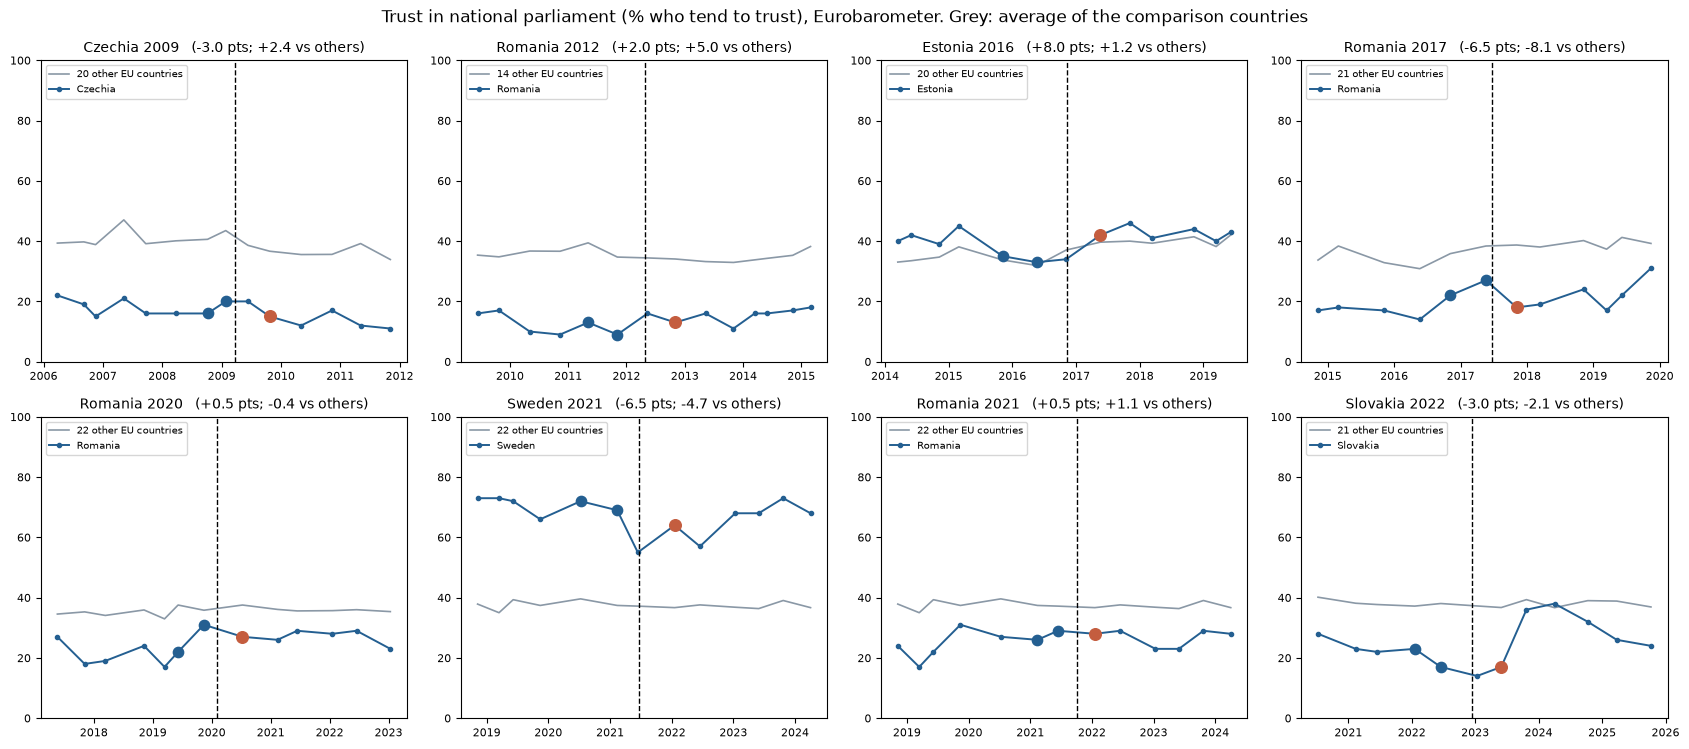

In [3]:
eb = load_waves()
par = eb[eb.institution == 'National parliament']

fig, axes = plt.subplots(2, 4, figsize=(17, 7.6))
for ax, r in zip(axes.flat, clean.itertuples()):
    code_ = ISO3_TO_EB[r.iso3]
    ev = r.event_date
    lo, hi = ev - pd.DateOffset(years=3), ev + pd.DateOffset(years=3)
    c = par[(par.country_code == code_) & par.start.between(lo, hi)].sort_values('start')
    group = r.parl_comparison_group.split(';')  # the same countries the numbers are compared with
    g = (par[par.country_code.isin(group) & par.start.between(lo, hi)].groupby('wave')
         .agg(start=('start', 'min'), trust=('trust', 'mean')).sort_values('start'))
    ax.plot(g.start, g.trust, color=GREY, lw=1.2, label=f'{len(group)} other EU countries')
    ax.plot(c.start, c.trust, color=BLUE, marker='o', ms=3, lw=1.4, label=COUNTRY[r.iso3])
    pre = set(r.parl_pre_waves.split('; '))
    p = c[c.start.dt.strftime('%Y-%m-%d').isin(pre)]
    ax.scatter(p.start, p.trust, s=55, color=BLUE, zorder=3)
    q = c[c.start == pd.Timestamp(r.parl_post_wave_start)]
    ax.scatter(q.start, q.trust, s=70, color=RED, zorder=3)
    ax.axvline(ev, color='black', ls='--', lw=1)
    ax.set_title(f"{r.episode}   ({r.parl_change_pp:+.1f} pts; {getattr(r, CHANGE):+.1f} vs others)", fontsize=10)
    ax.set_ylim(0, 100)
    ax.tick_params(labelsize=8)
    ax.legend(fontsize=7, loc='upper left')
fig.suptitle('Trust in national parliament (% who tend to trust), Eurobarometer. Grey: average of the comparison countries', fontsize=12)
plt.tight_layout()
plt.show()

## 4. How big were the changes?

Each dot is one episode: the change in trust from before to after, **minus** the change in other EU countries. The grey band is ±3 points, the usual sampling noise of a single survey. Filled blue dots are the 8 clean episodes; hollow grey dots are the three where an election intervenes; the red diamond is France, held out.

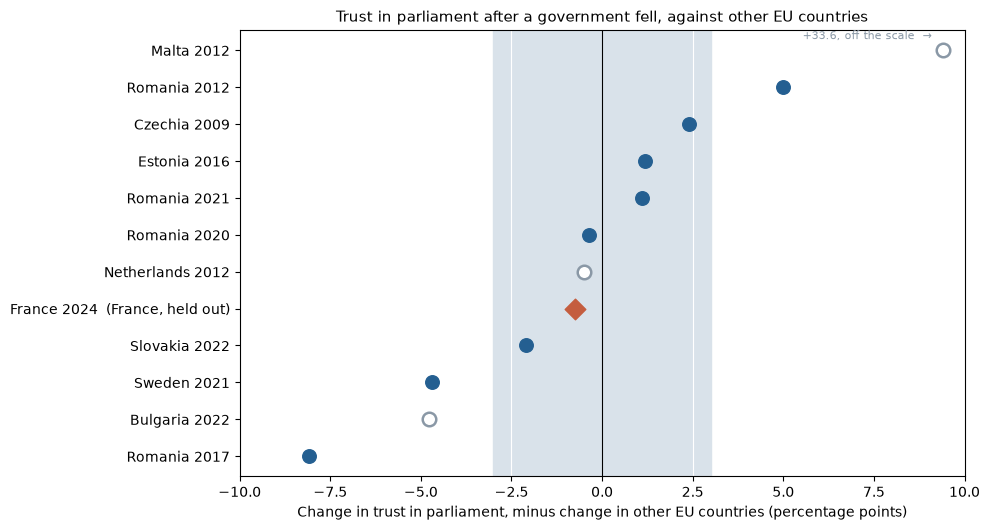

8 clean episodes: median +0.4, range -8.1 to +5.0.
Within the ±3 noise band: 5 of 8.  Outside it: Romania 2012 (+5.0), Romania 2017 (-8.1), Sweden 2021 (-4.7)
Up: 4, down: 4.


In [4]:
rows = pd.concat([clean.assign(kind='clean'), broad.assign(kind='broad'), pd.DataFrame([france]).assign(kind='france')])
rows = rows.dropna(subset=[CHANGE]).sort_values(CHANGE).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.axvspan(-3, 3, color=LIGHT, zorder=0)
ax.axvline(0, color='black', lw=0.8)
XMAX = 10
for y, r in rows.iterrows():
    x = min(r[CHANGE], XMAX - 0.6)
    if r.kind == 'clean':
        ax.scatter(x, y, s=95, color=BLUE, zorder=3)
    elif r.kind == 'broad':
        ax.scatter(x, y, s=95, facecolors='white', edgecolors=GREY, linewidths=1.8, zorder=3)
    else:
        ax.scatter(x, y, s=110, marker='D', color=RED, zorder=3)
    if r[CHANGE] > XMAX - 0.6:  # off the scale: keep the other points readable
        ax.annotate(f"{r[CHANGE]:+.1f}, off the scale  →", (x, y), textcoords='offset points', xytext=(-8, 8), ha='right', fontsize=8, color=GREY)
ax.set_xlim(-10, XMAX)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r.episode}{'  (France, held out)' if r.kind == 'france' else ''}" for r in rows.itertuples()])
ax.set_xlabel('Change in trust in parliament, minus change in other EU countries (percentage points)')
ax.set_title('Trust in parliament after a government fell, against other EU countries', fontsize=11)
ax.grid(axis='x', color='white')
plt.tight_layout()
plt.show()

v = clean[CHANGE]
print(f"8 clean episodes: median {v.median():+.1f}, range {v.min():+.1f} to {v.max():+.1f}.")
print(f"Within the ±3 noise band: {int((v.abs() <= 3).sum())} of {len(v)}.  Outside it: " +
      ', '.join(f"{r.episode} ({getattr(r, CHANGE):+.1f})" for r in clean[v.abs() > 3].itertuples()))
print(f"Up: {int((v > 0).sum())}, down: {int((v < 0).sum())}.")

## 5. Do the starting conditions line up with the change?

Each panel plots one thing known **when the government fell** against the change in trust. The last panel uses something known only afterwards (how long the country waited for a normal cabinet) and is shown for description only; it must never be used to predict. The red diamond is France. With 8 points there is **no fitted line**, only the points and a rank correlation.

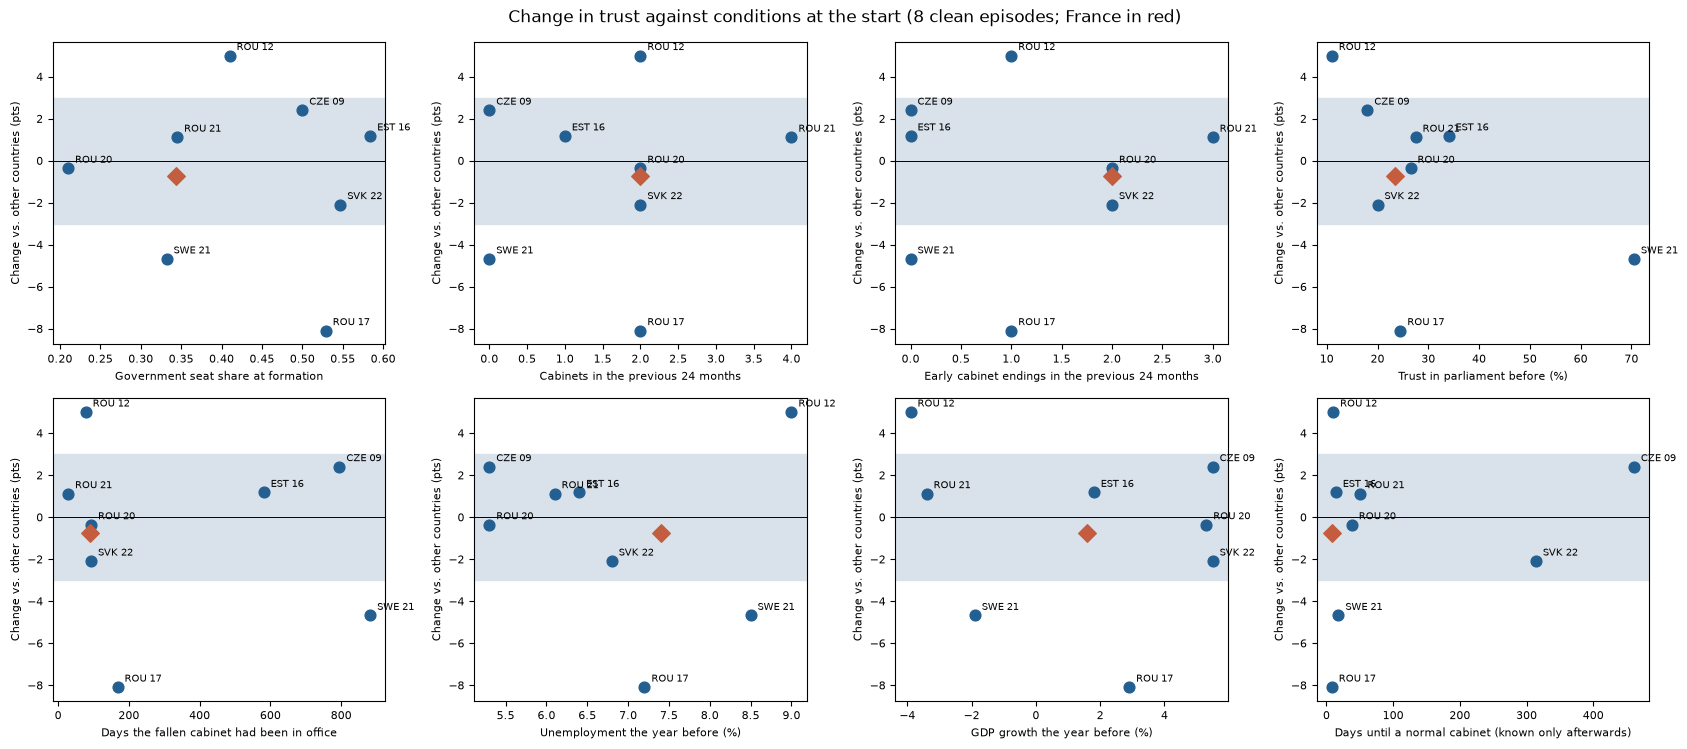

,Rank correlation
Variable,
Government seat share at formation,+0.07
Cabinets in the previous 24 months,-0.06
Early cabinet endings in the previous 24 months,-0.15
Trust in parliament before (%),-0.45
Days the fallen cabinet had been in office,-0.25
Unemployment the year before (%),-0.18
GDP growth the year before (%),-0.24
Days until a normal cabinet (known only afterwards),+0.19


In [5]:
PANELS = [
    ('government_seat_share', 'Government seat share at formation'),
    ('cabinets_24m_before', 'Cabinets in the previous 24 months'),
    ('early_endings_24m_before', 'Early cabinet endings in the previous 24 months'),
    ('parl_pre_trust_pct', 'Trust in parliament before (%)'),
    ('ending_cabinet_age_days', 'Days the fallen cabinet had been in office'),
    ('unemployment_pct', 'Unemployment the year before (%)'),
    ('gdp_growth_pct', 'GDP growth the year before (%)'),
    ('days_until_non_caretaker_cabinet', 'Days until a normal cabinet (known only afterwards)'),
]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.6))
rho = []
for ax, (col, label) in zip(axes.flat, PANELS):
    ax.axhspan(-3, 3, color=LIGHT, zorder=0)
    ax.axhline(0, color='black', lw=0.7)
    ax.scatter(clean[col], clean[CHANGE], s=60, color=BLUE, zorder=3)
    for r in clean.itertuples():
        ax.annotate(r.short, (getattr(r, col), getattr(r, CHANGE)), textcoords='offset points', xytext=(5, 4), fontsize=7)
    if pd.notna(france[col]) and pd.notna(france[CHANGE]):
        ax.scatter(france[col], france[CHANGE], s=80, marker='D', color=RED, zorder=4)
    ax.set_xlabel(label, fontsize=8)
    ax.set_ylabel('Change vs. other countries (pts)', fontsize=8)
    ax.tick_params(labelsize=8)
    # Spearman rank correlation = Pearson correlation of the ranks
    rho.append({'Variable': label, 'Rank correlation': clean[col].rank().corr(clean[CHANGE].rank())})
fig.suptitle('Change in trust against conditions at the start (8 clean episodes; France in red)', fontsize=12)
plt.tight_layout()
plt.show()
pd.DataFrame(rho).set_index('Variable').style.format('{:+.2f}')

**How to read the correlations.** With only 8 cases, a rank correlation has to be larger than about **0.74 (or below −0.74)** before it stands out from chance at the usual 5% level. Smaller values mean nothing can be said either way. Because several variables are tried, even a value above that line would need a second look.

In [6]:
strong = [r for r in rho if abs(r['Rank correlation']) >= 0.74]
if strong:
    print('Above the 0.74 line:', '; '.join(f"{r['Variable']} ({r['Rank correlation']:+.2f})" for r in strong))
else:
    print('No variable reaches the 0.74 line. With 8 cases, none of these conditions separates the larger falls from the smaller ones.')

No variable reaches the 0.74 line. With 8 cases, none of these conditions separates the larger falls from the smaller ones.


## 6. Other things that moved

Trust in government and in parties, turnout and the number of parties at the **next** parliamentary election, and the radical vote. Blanks mean the data do not exist yet (for example no later election). The next election can be years after the event, so these are weaker evidence than the trust figures. Radical vote excludes parties that PopuList marks as borderline.

In [7]:
o = pd.DataFrame({
    'Episode': clean.episode,
    'Government trust vs. others': clean.gov_change_beyond_comparison_pp,
    'Party trust vs. others': clean.parties_change_beyond_comparison_pp,
    'Next election': clean.next_election,
    'Turnout change': clean.turnout_change_pp,
    'Effective parties change': clean.effective_parties_change,
    'Radical vote change': clean.radical_change_pp,
}).set_index('Episode')
o.style.format({c: '{:+.1f}' for c in o.columns if c != 'Next election'}, na_rep='–')

,Government trust vs. others,Party trust vs. others,Next election,Turnout change,Effective parties change,Radical vote change
Episode,,,,,,
Czechia 2009,+21.3,+3.3,2010-05-29,-1.9,+2.7,-1.5
Romania 2012,+11.9,-0.5,2012-12-09,+1.2,-1.4,-1.9
Estonia 2016,-0.8,-4.5,2019-03-03,-0.6,+0.0,+9.6
Romania 2017,-12.8,-5.5,2020-12-06,-7.8,+1.6,+8.6
Romania 2020,+4.9,-0.8,2020-12-06,-7.8,+1.6,+8.6
Sweden 2021,+3.3,-7.3,2022-09-11,-3.0,-0.4,+3.0
Romania 2021,-2.3,+2.2,2024-12-01,+16.3,+2.0,+22.7
Slovakia 2022,+0.5,+2.0,2023-09-30,+2.7,-0.3,-10.4


## 7. France next to the eight

France's Barnier government fell on 4 December 2024. Here is France on the same starting conditions, against the range of the 8. *Inside* means France sits within the lowest and highest of the eight. This is a comparison, **not a forecast** for France.

In [8]:
rows = []
for col, label in PANELS[:-1]:
    lo, hi = clean[col].min(), clean[col].max()
    f = france[col]
    where = 'inside' if lo <= f <= hi else ('below' if f < lo else 'above')
    rank = int((clean[col] < f).sum()) + 1
    rows.append({'Starting condition': label, 'France': f, 'Lowest of 8': lo, 'Highest of 8': hi,
                 'Where France sits': f"{where} (would rank {rank} of 9 from the bottom)"})
cmp_ = pd.DataFrame(rows).set_index('Starting condition')
display(cmp_.style.format({'France': '{:.2f}', 'Lowest of 8': '{:.2f}', 'Highest of 8': '{:.2f}'}))
print(f"France, observed: trust {france.parl_pre_trust_pct:.1f}% before, {france.parl_post_trust_pct:.1f}% after "
      f"({france.parl_change_pp:+.1f} pts; {france[CHANGE]:+.1f} vs. other countries). "
      f"The 8 clean episodes ranged from {clean[CHANGE].min():+.1f} to {clean[CHANGE].max():+.1f}.")

,France,Lowest of 8,Highest of 8,Where France sits
Starting condition,,,,
Government seat share at formation,0.34,0.21,0.58,inside (would rank 3 of 9 from the bottom)
Cabinets in the previous 24 months,2.00,0.00,4.00,inside (would rank 4 of 9 from the bottom)
Early cabinet endings in the previous 24 months,2.00,0.00,3.00,inside (would rank 6 of 9 from the bottom)
Trust in parliament before (%),23.50,11.00,70.50,inside (would rank 4 of 9 from the bottom)
Days the fallen cabinet had been in office,90.00,28.00,882.00,inside (would rank 3 of 9 from the bottom)
Unemployment the year before (%),7.40,5.30,9.00,inside (would rank 7 of 9 from the bottom)
GDP growth the year before (%),1.60,-3.90,5.50,inside (would rank 4 of 9 from the bottom)


France, observed: trust 23.5% before, 24.0% after (+0.5 pts; -0.7 vs. other countries). The 8 clean episodes ranged from -8.1 to +5.0.


## 8. What this says, and what it does not

In [9]:
from IPython.display import Markdown
v = clean[CHANGE]
big = clean[v.abs() > 3]
low = clean[clean.parl_pre_trust_pct < 30]
low_names = ', '.join(low.episode)
lines = [
    f"- **Most of the eight barely moved.** {int((v.abs() <= 3).sum())} of 8 changed by 3 points or less against other EU countries, which is inside normal survey noise. The median is {v.median():+.1f}.",
    "- **" + str(len(big)) + " stand out:** " + ', '.join(f"{r.episode} ({getattr(r, CHANGE):+.1f})" for r in big.itertuples()) + ". "
    + ' and '.join(r.episode for r in big[big[CHANGE] < 0].itertuples()) + " fell; " + ' and '.join(r.episode for r in big[big[CHANGE] > 0].itertuples()) + " rose.",
    "- **The direction is mixed.** " + f"{int((v > 0).sum())} rose and {int((v < 0).sum())} fell, so a government falling does not by itself mean trust falls in the following months.",
    f"- **France is inside the range.** Its observed change ({france[CHANGE]:+.1f}) is within what the eight show. Its starting trust ({france.parl_pre_trust_pct:.1f}%) is low; {len(low)} of the eight also started below 30% ({low_names}).",
    ("- **No condition at the start lines up with the change** (section 5), though 8 cases could not show a weak link." if not strong
     else "- **Some conditions line up with the change** (section 5), but with 8 cases and several variables tried this needs a second look."),
]
Markdown('\n'.join(lines))

- **Most of the eight barely moved.** 5 of 8 changed by 3 points or less against other EU countries, which is inside normal survey noise. The median is +0.4.
- **3 stand out:** Romania 2012 (+5.0), Romania 2017 (-8.1), Sweden 2021 (-4.7). Romania 2017 and Sweden 2021 fell; Romania 2012 rose.
- **The direction is mixed.** 4 rose and 4 fell, so a government falling does not by itself mean trust falls in the following months.
- **France is inside the range.** Its observed change (-0.7) is within what the eight show. Its starting trust (23.5%) is low; 6 of the eight also started below 30% (Czechia 2009, Romania 2012, Romania 2017, Romania 2020, Romania 2021, Slovakia 2022).
- **No condition at the start lines up with the change** (section 5), though 8 cases could not show a weak link.

**What it cannot show**

- **No cause.** A change in trust after a government fell does not prove the fall caused it. Other events, the economy and the surveys' own noise all play a part.
- **Few and not independent.** 8 cases in 5 countries; 4 are Romanian. A few more or fewer cases would change the picture.
- **Overlaps remain.** Czechia 2009 and Romania 2012 sit in economic crises, Romania 2020 includes the start of COVID, and Romania 2020 and Sweden 2021 saw the same prime minister return. The *flags* column in section 2 records them.
- **Clean is a narrow test.** It rules out elections and other reviewed crises only, not every shock.
- **The 3 to 9 month window** was fixed in advance. A different window would give different numbers, and Eurobarometer surveys come twice a year.
- **Records still to check.** Official vote records for Romania 2012 and 2021 are not yet retrieved, and Orban's 2020 return date needs confirming.